<h3><center>Introduction to building a quant pricing library</center></h3>
<h1><center>Option Pricing by Partial Differential Equation using OOP</center></h1>
<h3><center>Abdulwahab, Animoku</center></h3>
<h4><center>28 October, 2026</center></h4>



## Option Pricing by PDE

<b>Goal of option pricing via PDE:<b>

* Use the Black Scholes PDE to price European Contract
* Use  different discretization scheme to achieve better results
* Compare the solution to the Analytical Pricer
* Price American Option with PDE method


<b>Extension<b>
* Calculate Greeks based on the different Schemes
* Extend PDE pricing scheme to Forward<b>

# Steps to achieve our Objectives
* Create Market Model
* Create European Contract using market inputs (underlying, Call/Put, Long/Short, strike, expiry)
* Create PDEParams using $dS, dt, S_{min_{multiplier}}, S_{max_{multiplier}} $ and method (implicit, explicit, CrankNicolson) as inputs
* Create EuropeanPDEPricer using the contract, model and PDEParams
* Calculate FV
* Visualize the Call and Put prices in 2D

In [1]:
import matplotlib.pyplot as plt

to_plot = [ {'data': [[0]*6, list(range(6))],
             'color':'r',
             'title':'Our interests'},
           {'data': [list(range(6))+[5]*6+list(range(6)), [0]*6+list(range(6))+[5]*6],
            'color' : 'g',
            'title' : 'Boundary and initial conditions'
           },] + [
           {'data': [[i]*6, list(range(6))],
            'color' : 'g',
            'title' : f'Step {5-i}'
           } for i in range(4,-1,-1)]
           

def my_illustration_plot(to_plot):
    fig,ax = plt.subplots(1)
    for x in to_plot:
        plt.scatter(*x['data'], s=300, c=x['color'])
        plt.title(x['title'])
#         plt.axis('on')
        plt.xlim(-1,6)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.xlabel("Time")
    plt.ylabel("Stock")
    plt.show()
    

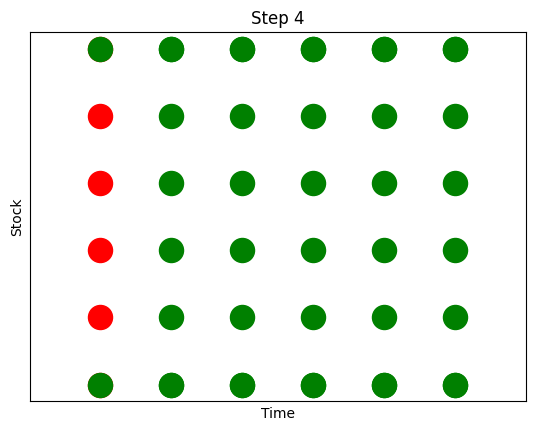

In [2]:
my_illustration_plot(to_plot[:6])

## Call and Put Option Pricing for European Options via PDE

Recall that the value $V$ of a Europoean option at time $t$, written on an underlying asset with price $S,$ satisfies the Black-Scholes equation
  $$ \frac{\delta V}{\delta t} + \frac{1}{2}\sigma^2 S^2\frac{\delta V^2}{\delta S^2} + rS \frac{\delta V}{\delta S} - rV =0,$$
 
with suitable terminal and boundary conditions:
$$V_C(S,T) = \max \{S-K,0 \}$$
$$V_P(S,T) = \max \{K-S,0 \}.$$
$$V_C(S_{\min}, t) = 0, V_C(S_{\max}, t) = S_{\max}- Ke^{-r(T-t)}, $$
$$V_P(S_{\max}, t) = 0, V_P(S_{\min}, t) = Ke^{-r(T-t)}-S_{\min}. $$

In [3]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

current = Path(Path().resolve())
sys.path.append(str(current))
sys.path.append(str(current.parents[2]))

from src.enums import *
from src.utils import *
from src.market_data import *
from src.pricer import *
# Make charts interactive
%matplotlib notebook

# Initialize market data
MarketData.initialize()

QuantCourseBP 9d2e0468d8070154466fc0c456ed5b6f25f47e3a*


# Utility function

In [4]:
"""The pricing function of European call option"""
def black_scholes_eur_call(spot, time_to_mat,sigma, strike, rate):
    d1_vec = ( np.log( spot / strike ) + ( rate + 0.5 * sigma**2 ) * time_to_mat ) / ( sigma * time_to_mat**0.5 )
    d2_vec = d1_vec - sigma * time_to_mat**0.5

    N_d1_vec = norm.cdf(d1_vec)
    N_d2_vec = norm.cdf(d2_vec)

    return N_d1_vec * spot - strike * np.exp((-1.0)*rate*time_to_mat) * N_d2_vec

# Create Test Example Contracts

In [5]:
und = Stock.TEST_COMPANY
expiry = 2.0
strike = 0.95 * MarketData.get_spot()[und]
ls = LongShort.LONG

In [6]:
derivative_type = [PutCallFwd.CALL, PutCallFwd.PUT]
model_types = [BSVolModel(und), FlatVolModel(und)]

contracts=[EuropeanContract(und, deriv_type, ls, strike, expiry) for deriv_type in derivative_type]
analytic_pricer = [EuropeanAnalyticPricer(contract, model_type, Params()) for contract in contracts for model_type in model_types]
analytical_fv= [pricer.calc_fair_value() for pricer in analytic_pricer]

print(f"FairValues:{analytical_fv}")

FairValues:[np.float64(23.60627624868423), np.float64(19.558965822125977), np.float64(9.565830962100371), np.float64(5.518520535542123)]


# Example with Explicit Method

* Create European Contract
* Create Market Model
* Create PDEParam
* Create EuropeanPDEPricer
* Calculate FV based on Explicit method
* Visualize the Call or Put prices in 2D 

In [7]:
params_exp = PDEParams(method = BSPDEMethod.EXPLICIT)

pde_exp_pricer = [EuropeanPDEPricer(contract, model_type, params_exp) for contract in contracts for model_type in model_types]
pde_exp_fv= [pricer.calc_fair_value() for pricer in pde_exp_pricer]

# pde_exp_pricer = [GenericPDEPricer(contract, model_type, params_exp) for contract in contracts for model_type in model_types]
# pde_exp_fv= [pricer.calc_fair_value() for pricer in pde_exp_pricer]


In [8]:
print(f"PDE Explicit method FairValues:{pde_exp_fv}")
print(f"Analytical method FairValues:{analytical_fv}")

PDE Explicit method FairValues:[np.float64(23.604447307816308), np.float64(19.559315913934707), np.float64(9.563828924282564), np.float64(5.518692809208318)]
Analytical method FairValues:[np.float64(23.60627624868423), np.float64(19.558965822125977), np.float64(9.565830962100371), np.float64(5.518520535542123)]


In [9]:
Errors = [f"{(price1-price2)/price1 *100:.4f}%" for price1, price2 in zip(pde_exp_fv, analytical_fv)]
print(f"Error between the Analytical and PDE Explicit method FairValues:{Errors}")

Error between the Analytical and PDE Explicit method FairValues:['-0.0077%', '0.0018%', '-0.0209%', '0.0031%']


# Attributes needed to create visualization

In [10]:
und_step = pde_exp_pricer[0].und_step
time_step = pde_exp_pricer[0].time_step
s_min= pde_exp_pricer[0].stock_min
s_max=pde_exp_pricer[0].stock_max
sigma = pde_exp_pricer[0].bsPDE.sigma
spot = pde_exp_pricer[0].initial_spot
rate = pde_exp_pricer[0].interest_rate
num_of_und_steps = pde_exp_pricer[0].bsPDE.num_of_und_steps

# Plot the graph for the first contract for different S values

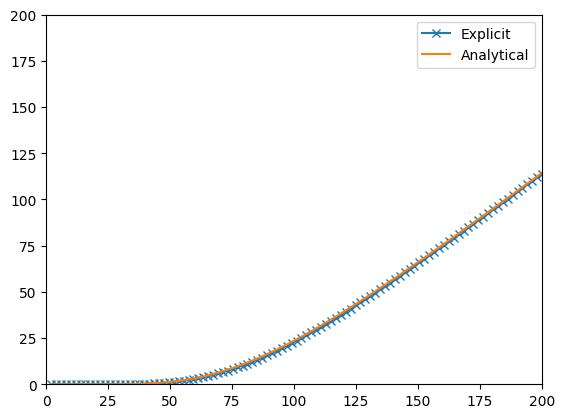

In [11]:
import matplotlib.pyplot as plt
sol_exp = pde_exp_pricer[0].grid[:,1]
Spots = np.linspace(s_min + und_step, s_max, num_of_und_steps+1)

%matplotlib inline
plt.plot(Spots, sol_exp, "x-", label="Explicit")
plt.plot(Spots, black_scholes_eur_call(Spots, expiry, sigma, strike, rate), label="Analytical")

plt.xlim(0, s_max)
plt.ylim(0,s_max)
plt.legend()
plt.show()

# Example with Non-Convergence with Explicit Params

In [12]:
params_exp = PDEParams(und_step = 0.01, time_step=0.001, method = BSPDEMethod.EXPLICIT)

pde_exp_pricer = EuropeanPDEPricer(contracts[0], model_types[0], params_exp) 
pde_exp_fv= pde_exp_pricer.calc_fair_value()


C:\Users\Temp\Git\QuantCourseBP\src\numerical_method.py:177: RuntimeWarning: overflow encountered in scalar add
  self.grid[i, j] = alpha[i] * self.grid[i - 1, j + 1] + beta[i] * self.grid[i, j + 1] + gamma[i] \
C:\Users\Temp\Git\QuantCourseBP\src\numerical_method.py:177: RuntimeWarning: overflow encountered in scalar multiply
  self.grid[i, j] = alpha[i] * self.grid[i - 1, j + 1] + beta[i] * self.grid[i, j + 1] + gamma[i] \
C:\Users\Temp\Git\QuantCourseBP\src\numerical_method.py:177: RuntimeWarning: invalid value encountered in scalar add
  self.grid[i, j] = alpha[i] * self.grid[i - 1, j + 1] + beta[i] * self.grid[i, j + 1] + gamma[i] \


In [13]:
print(f"PDE Explicit method FairValues:{pde_exp_fv}")

PDE Explicit method FairValues:nan


# Example with Implicit Method

* Create European Contract
* Create Market Model
* Create PDEParams
* Create EuropeanPDEPricer
* Calculate FV based on Implicit method
* Visualize the Call or Put prices in 2D

In [14]:
param_imp = PDEParams(method = BSPDEMethod.IMPLICIT)

pde_imp_pricer = [EuropeanPDEPricer(contract, model_type, param_imp) for contract in contracts for model_type in model_types]
pde_imp_fv= [pricer.calc_fair_value() for pricer in pde_imp_pricer]

In [15]:
print(f"PDE Implicit method FairValues:{pde_imp_fv}")
print(f"Analytical method FairValues:{analytical_fv}")

PDE Implicit method FairValues:[np.float64(23.60198913553196), np.float64(19.557755216197634), np.float64(9.562097627250461), np.float64(5.5176052392037995)]
Analytical method FairValues:[np.float64(23.60627624868423), np.float64(19.558965822125977), np.float64(9.565830962100371), np.float64(5.518520535542123)]


In [16]:
Errors_imp = [f"{(price1-price2)/price1 *100:.4f}%" for price1, price2 in zip(pde_imp_fv,analytical_fv)]
print(f"Error between the Analytical and PDE Explicit method FairValues:{Errors_imp}")

Error between the Analytical and PDE Explicit method FairValues:['-0.0182%', '-0.0062%', '-0.0390%', '-0.0166%']


# Compare Implicit Method with Analytical Pricer

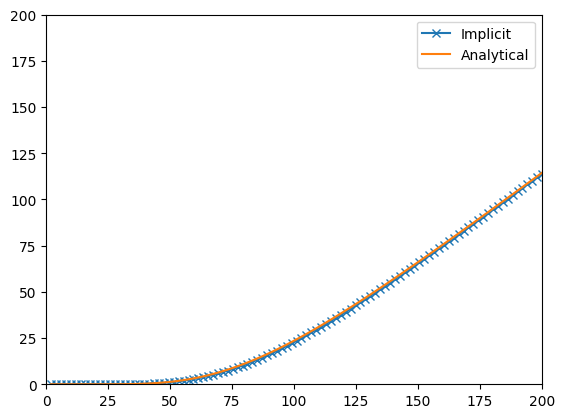

In [17]:
sol_imp = pde_imp_pricer[0].grid[:,1]


plt.plot(Spots, sol_imp, "x-", label="Implicit")
plt.plot(Spots, black_scholes_eur_call(Spots, expiry, sigma, strike, rate), label="Analytical")

plt.xlim(0, s_max)
plt.ylim(0,s_max)
plt.legend()
plt.show()

# Example with Crank Nicolson Method

* Create European Contract
* Create Market Model
* Create PDEParams
* Create GenericPDEPricer
* Calculate FV and Greeks based on Crank_Nicolson methods
* Visualize the Call and Put prices in 2D and 3D

In [18]:
param_crn = PDEParams(method = BSPDEMethod.CRANK_NICOLSON)

pde_crn_pricer = [EuropeanPDEPricer(contract, model_type, param_crn) for contract in contracts for model_type in model_types]
pde_crn_fv= [pricer.calc_fair_value() for pricer in pde_crn_pricer]


In [19]:
print(f"PDE Crank-Nicolson method FairValues:{pde_crn_fv}")
print(f"Analytical method FairValues:{analytical_fv}")

PDE Crank-Nicolson method FairValues:[np.float64(23.6034086340357), np.float64(19.558594355475716), np.float64(9.562963346249866), np.float64(5.518149067657358)]
Analytical method FairValues:[np.float64(23.60627624868423), np.float64(19.558965822125977), np.float64(9.565830962100371), np.float64(5.518520535542123)]


In [20]:
Errors_crn = [f"{(price1-price2)/price1 *100:.4f}%" for price1, price2 in zip(pde_crn_fv,analytical_fv)]
print(f"Error between the Analytical and PDE Crank Nicolson method FairValues:{Errors_crn}")

Error between the Analytical and PDE Crank Nicolson method FairValues:['-0.0121%', '-0.0019%', '-0.0300%', '-0.0067%']


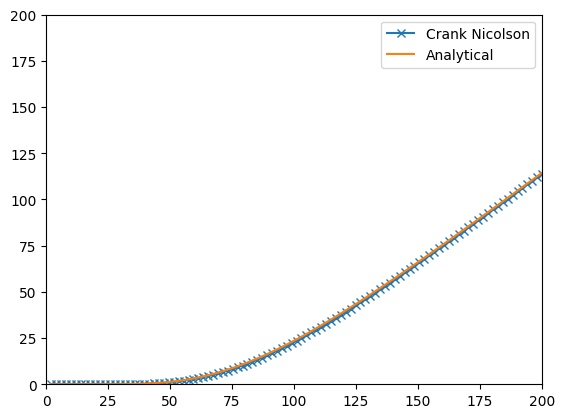

In [21]:
sol_imp = pde_crn_pricer[0].grid[:,1]

plt.plot(Spots, sol_imp, "x-", label="Crank Nicolson")
plt.plot(Spots, black_scholes_eur_call(Spots, expiry, sigma, strike, rate), label="Analytical")

plt.xlim(0, s_max)
plt.ylim(0,s_max)
plt.legend()
plt.show()

# Pricing American Option with Black Scholes PDE

<b>Properties of American Option:<b>
* The price of an American Option is atleast as much as the European Option with the same properties:
  $V_t^{am} \geq V_t^{eur}, \ for \, any\, \;  t \in [0,T]$
* An American option has at least the value of the payoff at any time $t.$
* There are different numerical techniques to price an American Option: LongStaff-Schwarz, PDE, Tree methods 
* American Call contract will never be exercised early unless the stock has a dividend.
* For a sufficient Low Price an American Put will be exercised

<b>Consider the Porfolio:<b>
* Consider an American put has a value lower than $(K-S)^+$
Strategy:
* Take Long positions in both the Asset and in the money Put Option
* Exercise the Put option immediately and sell the stock at higher price K. 
* This creates an arbitrage opportunity until the Put price becomes at least the payoff.
* Thus,
$$V_{t,c}^{am} \geq \max(S_t - K,0), \ for \, any\, \;  t \in [0,T]$$
$$V_{t,p}^{am} \geq \max(K- S_t,0), \ for \, any\, \;  t \in [0,T]$$

In [22]:
params_exp = PDEParams(method = BSPDEMethod.CRANK_NICOLSON)
contracts=[AmericanContract(und, deriv_type, ls, strike, expiry) for deriv_type in derivative_type]

pde_exp_pricer = [AmericanPDEPricer(contract, model_type, params_exp) for contract in contracts for model_type in model_types]
pde_exp_fv= [pricer.calc_fair_value() for pricer in pde_exp_pricer]

In [23]:
model_types

In [24]:
print(f"PDE Explicit method FairValues:{pde_exp_fv}")

PDE Explicit method FairValues:[np.float64(23.6034086340357), np.float64(19.558594355475716), np.float64(10.449941938430443), np.float64(6.2803811513002366)]


# Conclusion

* We have seen the implemention of European Call/Put options pricing via PDE methods
* Which method is faster?

<b> Project Ideas <b>

* Implement Forward pricing on the Grid
* Implement the Greeks using the bump and re-evaluation method

# Pricing a Best-of-Two-Assets European Contract

We consider two independent stock processes with equal volatility.

The risk-neutral stock price dynamics are:

$$
dS_1=rS_1dt+\sigma S_1dW_1
$$

$$
dS_2=rS_2dt+\sigma S_2dW_2
$$

The initial stock prices are:

$$
S_1(0)=S_2(0)=100
$$

The stocks are independent, so their correlation is zero:

$$
\rho=0
$$

The contract pays the maximum of the two stock prices at maturity:

$$
V(T)=\max(S_1(T),S_2(T))
$$

We assume constant volatility, a constant risk-free interest rate and no dividends.

## (a) Analytical Fair Value

Using the identity:

$$
\max(S_1,S_2)=S_2+(S_1-S_2)^+
$$

The contract can be decomposed into a position in stock 2 and a European exchange option.

The exchange option can be priced using the Margrabe formula.

The effective volatility is:

$$
\sigma_M=\sqrt{\sigma_1^2+\sigma_2^2}
=\sqrt{2}\sigma
$$

The Margrabe parameters are:

$$
d_1=\frac{\sigma_M\sqrt{T}}{2}
=\sigma\sqrt{\frac{T}{2}}
$$

$$
d_2=-d_1
$$

Therefore, the fair value is:

$$
V_0=S_1(0)N(d_1)+S_2(0)N(-d_2)
$$

Equivalently:

$$
\boxed{
V_0=S_1(0)N\left(\sigma\sqrt{\frac{T}{2}}\right)
+S_2(0)N\left(\sigma\sqrt{\frac{T}{2}}\right)
}
$$

Since both initial stock prices equal 100:

$$
\boxed{
V_0=200N\left(\sigma\sqrt{\frac{T}{2}}\right)
}
$$

The risk-free rate cancels out because the contract is an exchange option between two non-dividend-paying stocks.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Initial stock prices
S1_0 = 100
S2_0 = 100

# Market parameters (replace with actual market inputs)
sigma = 0.20
r = 0.05
T = 1.0

# Analytical pricing using Margrabe formula
def analytical_fair_value(S1, S2, sigma, T):
    d1 = sigma * np.sqrt(T / 2)
    return S1 * norm.cdf(d1) + S2 * norm.cdf(d1)

analytical_fv = analytical_fair_value(
    S1_0, S2_0, sigma, T
)

print(f"Analytical Fair Value: {analytical_fv:.6f}")

Analytical Fair Value: 111.246292


## (b) Derivation of the Partial Differential Equation

Let the value of the contract be:

$$
V=V(S_1,S_2,t)
$$

Applying Itô's lemma:

$$
\begin{aligned}
dV={}&V_tdt+V_{S_1}dS_1+V_{S_2}dS_2\\
&+\frac12 V_{S_1S_1}(dS_1)^2
+\frac12 V_{S_2S_2}(dS_2)^2\\
&+V_{S_1S_2}dS_1dS_2
\end{aligned}
$$

Since the two stocks are independent:

$$
dW_1dW_2=0
$$

Therefore, the cross-derivative term disappears.

Using the risk-neutral pricing principle, the resulting Black-Scholes PDE is:

$$
\boxed{
\begin{aligned}
V_t
&+\frac12\sigma^2S_1^2V_{S_1S_1}
+\frac12\sigma^2S_2^2V_{S_2S_2}\\
&+rS_1V_{S_1}
+rS_2V_{S_2}
-rV=0
\end{aligned}
}
$$

### Terminal condition

At maturity, the contract pays the maximum of the two stocks:

$$
\boxed{
V(S_1,S_2,T)=\max(S_1,S_2)
}
$$

### Boundary conditions

When the first stock is zero:

$$
V(0,S_2,t)=S_2
$$

When the second stock is zero:

$$
V(S_1,0,t)=S_1
$$

For sufficiently large stock prices, we approximate the upper boundaries by:

$$
V(S_{\max},S_2,t)=S_{\max}
$$

$$
V(S_1,S_{\max},t)=S_{\max}
$$

## (c) Solving the PDE Using the Finite Difference Method

To solve the PDE numerically, introduce time to maturity:

$$
\tau=T-t
$$

The PDE becomes:

$$
\begin{aligned}
V_\tau={}&
\frac12\sigma^2S_1^2V_{S_1S_1}
+\frac12\sigma^2S_2^2V_{S_2S_2}\\
&+rS_1V_{S_1}+rS_2V_{S_2}-rV
\end{aligned}
$$

We use central finite differences for the first and second derivatives.

For the first stock:

$$
V_{S_1}\approx
\frac{V_{i+1,j}-V_{i-1,j}}{2\Delta S}
$$

$$
V_{S_1S_1}\approx
\frac{V_{i+1,j}-2V_{i,j}+V_{i-1,j}}{\Delta S^2}
$$

The same approximations are applied to the second stock.

We use an explicit finite-difference scheme, starting from the terminal payoff and working backwards to time zero.

The solution is calculated on a two-dimensional stock price grid.

In [27]:
def solve_pde(sigma, r, T, S0=100, Smax=400, N=80):

    dS = Smax / N
    S = np.linspace(0, Smax, N + 1)

    # Explicit scheme stability condition
    dt_max = 0.4 / (
        sigma**2 * N**2 + r * N + r
    )

    Nt = int(np.ceil(T / dt_max))
    dt = T / Nt

    # Terminal payoff
    V = np.maximum(
        S[:, None],
        S[None, :]
    )

    # Backward time stepping
    for n in range(Nt):

        V_new = V.copy()

        # First derivatives
        dVdS1 = (
            V[2:, 1:-1] - V[:-2, 1:-1]
        ) / (2 * dS)

        dVdS2 = (
            V[1:-1, 2:] - V[1:-1, :-2]
        ) / (2 * dS)

        # Second derivatives
        d2VdS1 = (
            V[2:, 1:-1]
            - 2 * V[1:-1, 1:-1]
            + V[:-2, 1:-1]
        ) / dS**2

        d2VdS2 = (
            V[1:-1, 2:]
            - 2 * V[1:-1, 1:-1]
            + V[1:-1, :-2]
        ) / dS**2

        S1 = S[1:-1, None]
        S2 = S[None, 1:-1]

        # Two-dimensional Black-Scholes PDE
        operator = (
            0.5 * sigma**2 * S1**2 * d2VdS1
            + 0.5 * sigma**2 * S2**2 * d2VdS2
            + r * S1 * dVdS1
            + r * S2 * dVdS2
            - r * V[1:-1, 1:-1]
        )

        # Explicit finite difference update
        V_new[1:-1, 1:-1] = (
            V[1:-1, 1:-1] + dt * operator
        )

        # Boundary conditions
        V_new[0, :] = S
        V_new[:, 0] = S
        V_new[-1, :] = Smax
        V_new[:, -1] = Smax

        V = V_new

    # Initial stock prices
    i = int(S0 / dS)

    return V[i, i], V, S, dt, Nt


pde_fv, pde_grid, S, dt, Nt = solve_pde(
    sigma=sigma,
    r=r,
    T=T,
    S0=100
)

print(f"PDE Fair Value: {pde_fv:.6f}")
print(f"Number of time steps: {Nt}")
print(f"Time step: {dt:.8f}")

PDE Fair Value: 111.203298
Number of time steps: 651
Time step: 0.00153610


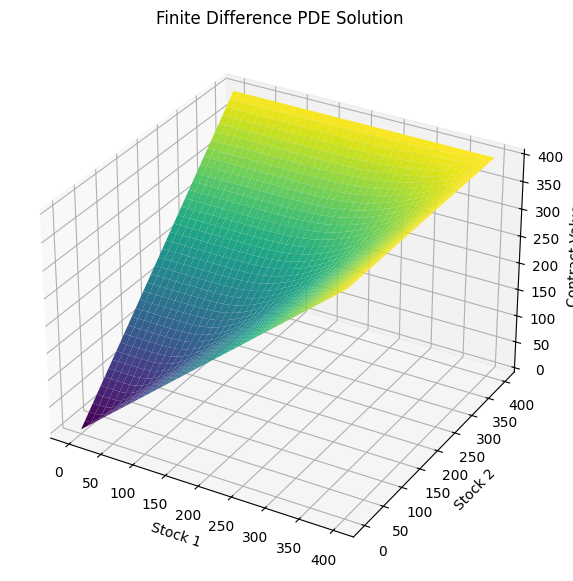

In [28]:
from mpl_toolkits.mplot3d import Axes3D

S1_grid, S2_grid = np.meshgrid(
    S, S, indexing="ij"
)

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    S1_grid,
    S2_grid,
    pde_grid,
    cmap="viridis"
)

ax.set_xlabel("Stock 1")
ax.set_ylabel("Stock 2")
ax.set_zlabel("Contract Value")

ax.set_title("Finite Difference PDE Solution")

plt.show()

## (d) Pricing Using Monte Carlo Simulation

We simulate the two independent stock prices under the risk-neutral measure.

The terminal stock prices are:

$$
S_i(T)=S_i(0)\exp\left[
\left(r-\frac12\sigma^2\right)T
+\sigma\sqrt{T}Z_i
\right]
$$

where:

$$
Z_1,Z_2\sim N(0,1)
$$

Since the stocks are independent:

$$
\operatorname{Corr}(Z_1,Z_2)=0
$$

For each simulation, the contract payoff is:

$$
V(T)=\max(S_1(T),S_2(T))
$$

The Monte Carlo estimator is:

$$
\boxed{
V_0^{MC}=
e^{-rT}\frac{1}{M}
\sum_{k=1}^{M}
\max(S_1^{(k)}(T),S_2^{(k)}(T))
}
$$

where M is the number of simulations.

In [29]:
def monte_carlo_pricer(
    S1, S2, sigma, r, T,
    num_simulations=1_000_000
):

    # Independent random variables
    Z1 = np.random.standard_normal(num_simulations)
    Z2 = np.random.standard_normal(num_simulations)

    # Simulate terminal stock prices
    ST1 = S1 * np.exp(
        (r - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z1
    )

    ST2 = S2 * np.exp(
        (r - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z2
    )

    # Contract payoff
    payoff = np.maximum(ST1, ST2)

    # Discounted payoff
    discounted_payoff = np.exp(-r * T) * payoff

    # Monte Carlo estimate
    mc_fv = np.mean(discounted_payoff)

    # Standard error
    standard_error = (
        np.std(discounted_payoff, ddof=1)
        / np.sqrt(num_simulations)
    )

    return mc_fv, standard_error


mc_fv, mc_se = monte_carlo_pricer(
    S1=S1_0,
    S2=S2_0,
    sigma=sigma,
    r=r,
    T=T
)

print(f"Monte Carlo Fair Value: {mc_fv:.6f}")
print(f"Monte Carlo Standard Error: {mc_se:.6f}")

Monte Carlo Fair Value: 111.271190
Monte Carlo Standard Error: 0.018725


In [30]:
results = {
    "Analytical": analytical_fv,
    "Finite Difference PDE": pde_fv,
    "Monte Carlo": mc_fv
}

print("Fair Value Comparison")
print("-" * 45)

for method, value in results.items():
    print(f"{method:<25}: {value:.6f}")

print("-" * 45)

pde_error = abs(pde_fv - analytical_fv) / analytical_fv * 100

mc_error = abs(mc_fv - analytical_fv) / analytical_fv * 100

print(f"PDE Relative Error: {pde_error:.4f}%")
print(f"Monte Carlo Relative Error: {mc_error:.4f}%")
print(f"Monte Carlo Standard Error: {mc_se:.6f}")

Fair Value Comparison
---------------------------------------------
Analytical               : 111.246292
Finite Difference PDE    : 111.203298
Monte Carlo              : 111.271190
---------------------------------------------
PDE Relative Error: 0.0386%
Monte Carlo Relative Error: 0.0224%
Monte Carlo Standard Error: 0.018725


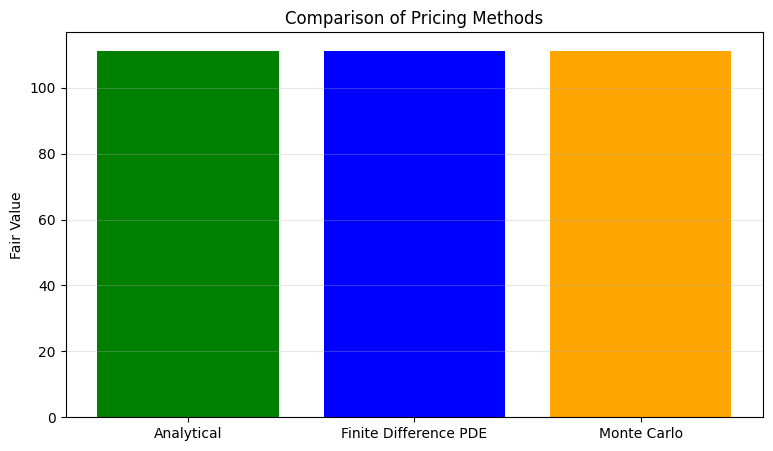

In [31]:
methods = list(results.keys())
values = list(results.values())

plt.figure(figsize=(9, 5))

plt.bar(
    methods,
    values,
    color=["green", "blue", "orange"]
)

plt.ylabel("Fair Value")
plt.title("Comparison of Pricing Methods")
plt.grid(axis="y", alpha=0.3)

plt.show()

## Conclusion

The fair value of the best-of-two-assets contract was derived analytically using the Margrabe exchange option formula.

The corresponding two-dimensional Black-Scholes PDE was derived using Itô's lemma and the risk-neutral pricing principle.

The PDE was solved numerically using an explicit finite-difference scheme, while Monte Carlo simulation was used as an independent numerical pricing method.

The three methods should produce similar fair values.

Small differences arise from:

- Finite-difference discretization and boundary approximations.
- Monte Carlo sampling error.
- The number of grid points and simulations used.

Increasing the grid resolution and the number of Monte Carlo simulations improves numerical accuracy.

Overall, the analytical solution provides a benchmark for validating both numerical methods.